# 실습2

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100

In [18]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)
  ax.axvline(0, color='black', alpha=0.3)
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')

In [19]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [20]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

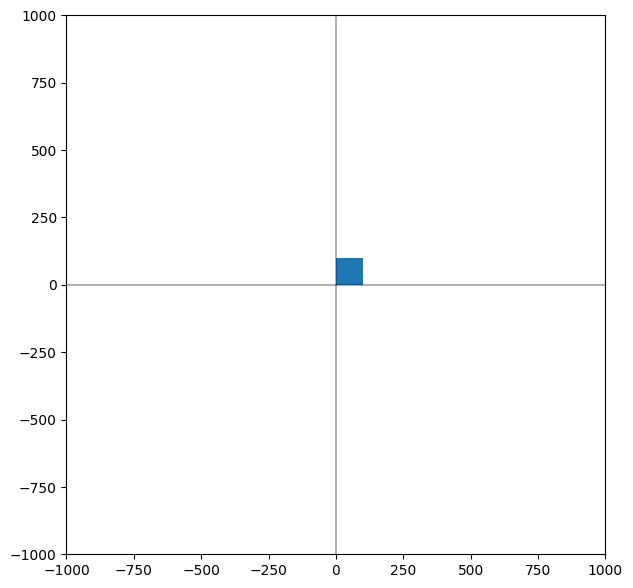

In [21]:
fig, ax = plt.subplots(figsize=(7,7))

draw_axis(ax)

draw_object(ax)

plt.show()

In [22]:
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [23]:
def draw_cockpit(ax, p1, p2, p3, p4): # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  """
  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)
  """

  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [24]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

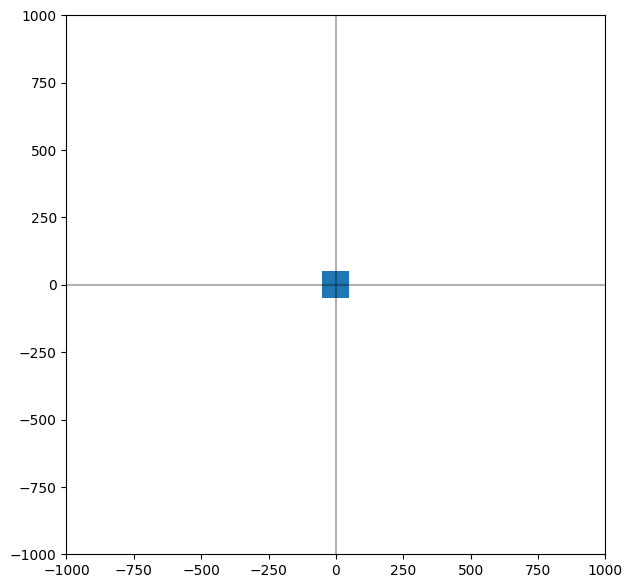

In [25]:
fig, ax = plt.subplots(figsize=(7,7))

draw_axis(ax)

draw_object(ax)

plt.show()

# Tie Fighter 그리기


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100

In [27]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)
  ax.axvline(0, color='black', alpha=0.3)
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')


def draw_rectangle(ax, p1, p2, p3, p4, color=None):
  my_polygon = Polygon([p1, p2, p3, p4], color=color)
  ax.add_patch(my_polygon)

In [28]:
def apply(m, p):
  hp = np.array([p[0], p[1], 1.0]) # 동차좌표계로 변환
  q = np.dot(m, hp)                # 행렬과 벡터의 곱 (3,3) x (3,) -> (3,)
  return np.array([q[0], q[1]])    # 2차원 좌표계로 변환

# q = T(dx, dy) p
def translate(p, dx, dy):
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])
  return apply(m, p)

# q = R(theta) p
def rotate(p, theta):
  c, s = np.cos(theta), np.sin(theta)
  m = np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])
  return apply(m, p)

# q = S(sx, sy) p
def scale(p, sx, sy):
  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])
  return apply(m, p)

# x' = x + sx * y
def shear_x(p, sx):
  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
  return apply(m, p)

# y' = y + sy * x
def shear_y(p, sy):
  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])
  return apply(m, p)

# x축 기준 반전
def reflect_x(p):
  m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
  return apply(m, p)

# y축 기준 반전
def reflect_y(p):
  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
  return apply(m, p)

# 원점 기준 반전
def reflect_origin(p):
  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
  return apply(m, p)

# y = x 기준 반전
def reflect_yx(p):
  m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
  return apply(m, p)


# 점 여러 개에 같은 변환을 한꺼번에 적용
def transform(pts, func, *args):
  return [func(p, *args) for p in pts]

In [29]:
def draw_cockpit(ax, p1, p2, p3, p4): # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, np.pi/4)
  q2 = rotate(q2, np.pi/4)
  q3 = rotate(q3, np.pi/4)
  q4 = rotate(q4, np.pi/4)

  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [30]:
def arm_parts(p1, p2, p3, p4):
  upper = transform([p1, p2, p3, p4], scale, 5, 0.75)
  upper = transform(upper, shear_y, 0.13)
  upper = transform(upper, translate, -750, -30)
  lower = transform(upper, reflect_x)
  return [upper, lower]


def draw_left_arm(ax, p1, p2, p3, p4): # 왼쪽 날개축
  for part in arm_parts(p1, p2, p3, p4):
    draw_rectangle(ax, *part)


def draw_right_arm(ax, p1, p2, p3, p4):
  for part in arm_parts(p1, p2, p3, p4):
    draw_rectangle(ax, *transform(part, reflect_y))


def wing_parts(p1, p2, p3, p4):
  upper = transform([p1, p2, p3, p4], scale, 1, 6)
  upper = transform(upper, shear_y, -2)
  upper = transform(upper, translate, -850, 0)
  lower = transform(upper, reflect_x)
  return [upper, lower]


def draw_left_wing(ax, p1, p2, p3, p4): # 왼쪽 날개
  for part in wing_parts(p1, p2, p3, p4):
    draw_rectangle(ax, *part)


def draw_right_wing(ax, p1, p2, p3, p4): # 오른쪽 날개 = 왼쪽 날개를 y축 기준 반전
  for part in wing_parts(p1, p2, p3, p4):
    draw_rectangle(ax, *transform(part, reflect_y))

In [31]:
# tiefighter 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_left_wing(ax, p1, p2, p3, p4) # 3. 왼쪽 날개
  draw_right_wing(ax, p1, p2, p3, p4)# 5. 오른쪽 날개
  draw_left_arm(ax, p1, p2, p3, p4)  # 2. 왼쪽 날개축
  draw_right_arm(ax, p1, p2, p3, p4) # 4. 오른쪽 날개축
  draw_cockpit(ax, p1, p2, p3, p4)   # 1. 중앙 조종석 (마지막에 그려서 위에 보이게)

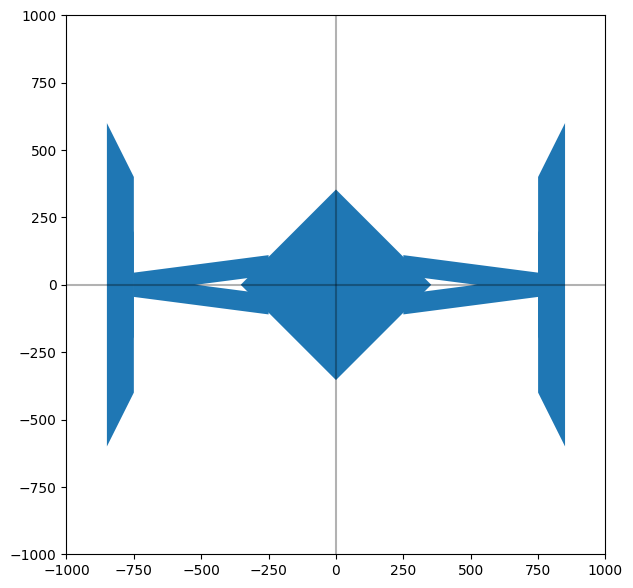

In [32]:
fig, ax = plt.subplots(figsize=(7,7))

draw_axis(ax)

draw_object(ax)

plt.show()